# SECOM Semiconductor Defect Detection

## 1. Problem statement
Semiconductor wafers are tested only at the end of the process, so defects are found late and cost a lot.

**Goal:** predict whether a wafer will fail from its 590 in-process sensor readings plus 3 derived features ("n_missing", "hour", "dayofweek"), so engineers can inspect high-risk wafers early.

**Measurable targets:** only ~6.6% of wafers fail, so accuracy is misleading (always predicting "Pass" gets ~93%). I optimise **PR-AUC** and **Fail recall / F2** (missed defects are costly) and compare every model with a majority-class baseline.

**Dataset:** UCI SECOM (real fab data): 1,567 wafers, 590 sensors, ~104 fails, with timestamps. It is non-trivial: high-dimensional, noisy, heavily imbalanced and about 4.5% missing values.

In [50]:

%pip install -q ucimlrepo imbalanced-learn xgboost

In [51]:
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## 2. Load data, quality checks and feature engineering

In [52]:
from ucimlrepo import fetch_ucirepo

df = fetch_ucirepo(id=179).data.original.copy()

raw_ts = df["timestamp"].copy()   # keep the original text for checking
df["timestamp"] = pd.to_datetime(raw_ts, dayfirst=True, errors="coerce", format="mixed")
print("Unparseable timestamps:", df["timestamp"].isna().sum())
print(raw_ts[df["timestamp"].isna()].head())   # shows examples that still fail

df = df.sort_values("timestamp").reset_index(drop=True)

# Data quality checks
print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate rows (ignoring timestamp):", df.drop(columns="timestamp").duplicated().sum())
print(df.dtypes.value_counts())
print("Total missing values: %d (%.2f%% of all readings)" %
      (df.isnull().sum().sum(), df.isnull().sum().sum() / df.size * 100))

y = (df["class"] == 1).astype(int)          # 1 = Fail, 0 = Pass
X = df.drop(columns=["class", "timestamp"]).copy()

# Feature engineering (row-level only, so no leakage)
X["n_missing"] = X.isnull().sum(axis=1)     # many missing readings may signal a faulty run
X["hour"] = df["timestamp"].dt.hour
X["dayofweek"] = df["timestamp"].dt.dayofweek
print(df["timestamp"].isna().sum())
print("Feature matrix:", X.shape, "| Fail rate: %.2f%%" % (y.mean() * 100))

Unparseable timestamps: 0
Series([], Name: timestamp, dtype: object)
Shape: (1567, 592)
Duplicate rows: 0
Duplicate rows (ignoring timestamp): 0
float64           590
int64               1
datetime64[ns]      1
Name: count, dtype: int64
Total missing values: 41951 (4.52% of all readings)
0
Feature matrix: (1567, 593) | Fail rate: 6.64%


## 3. Exploratory data analysis

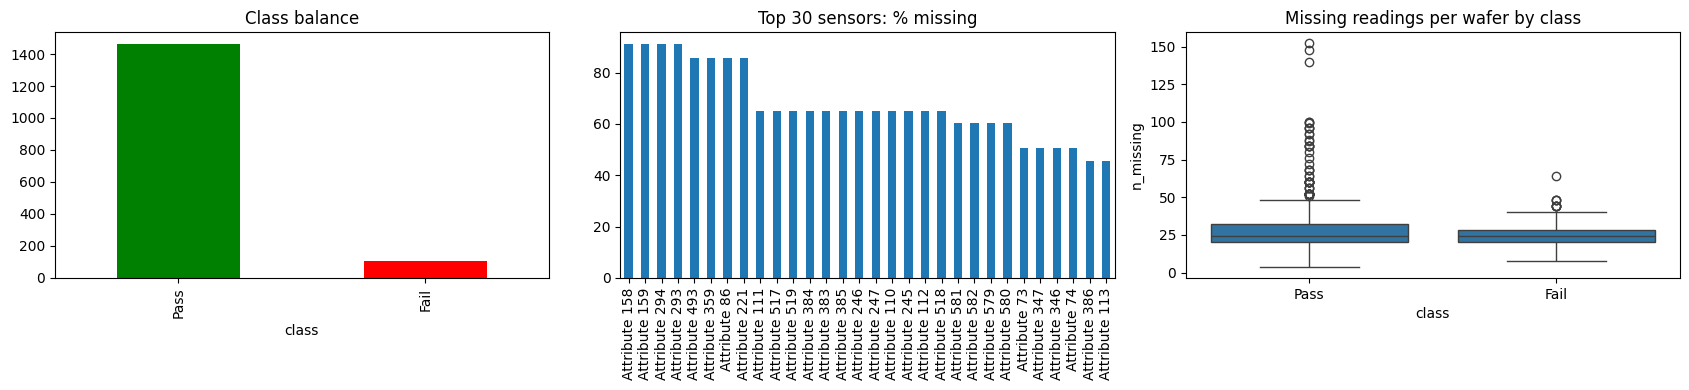

Fail rate by weekday:
dayofweek
0    0.070
1    0.043
2    0.074
3    0.064
4    0.054
5    0.064
6    0.106
Name: class, dtype: float64

Sensors with >50% missing: 28
Constant sensors: 116


In [53]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

y.map({0: "Pass", 1: "Fail"}).value_counts().plot(kind="bar", ax=ax[0], color=["green", "red"])
ax[0].set_title("Class balance")

(X.isnull().mean() * 100).sort_values(ascending=False).head(30).plot(kind="bar", ax=ax[1])
ax[1].set_title("Top 30 sensors: % missing")

sns.boxplot(x=y.map({0: "Pass", 1: "Fail"}), y=X["n_missing"], ax=ax[2])
ax[2].set_title("Missing readings per wafer by class")
plt.tight_layout()
plt.show()

print("Fail rate by weekday:")
print(y.groupby(X["dayofweek"]).mean().round(3))
print("\nSensors with >50% missing:", (X.isnull().mean() > 0.5).sum())
print("Constant sensors:", (X.nunique(dropna=True) <= 1).sum())

## 4. Train/test split (before any fitting, to avoid leakage)

In [54]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# Drop columns with >50% missing, using TRAIN statistics only
keep_cols = X_train.columns[X_train.isnull().mean() <= 0.50]
X_train, X_test = X_train[keep_cols], X_test[keep_cols]

print("Train:", X_train.shape, "| train fails:", y_train.sum())
print("Test :", X_test.shape, "| test fails:", y_test.sum())

Train: (1253, 569) | train fails: 83
Test : (314, 569) | test fails: 21


## 5. Preprocessing pipeline (imputation, outlier clipping, scaling and SMOTE all happen inside each CV fold)

In [55]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline


class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each sensor to the [1%, 99%] range learned from the training data (outlier handling)."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper

    def fit(self, X, y=None):
        self.lo_ = np.nanquantile(X, self.lower, axis=0)
        self.hi_ = np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(X, self.lo_, self.hi_)


def make_pipe(model, smote=True):
    steps = [
        ("impute", SimpleImputer(strategy="median")),
        ("clip", Winsorizer()),
        ("var", VarianceThreshold(0.0)),   # removes constant sensors
        ("scale", StandardScaler()),
    ]
    if smote:
        steps.append(("smote", SMOTE(random_state=SEED)))   # only applied to training folds
    steps.append(("model", model))
    return ImbPipeline(steps)

## 6. Baseline and models with cross-validation (training data only)

In [56]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, fbeta_score

from sklearn.svm import SVC


models = {
    "Baseline (majority)": make_pipe(DummyClassifier(strategy="most_frequent"), smote=False),
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=3000, random_state=SEED)),
    "SVM (RBF)": make_pipe(SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED)),   # SMOTE balances classes
    "Random Forest": make_pipe(
        RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                               random_state=SEED, n_jobs=-1), smote=False),

}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
}

rows = []
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name, **{k: "%.3f +/- %.3f" % (res["test_" + k].mean(), res["test_" + k].std())
                                   for k in scoring}})
cv_table = pd.DataFrame(rows)
print(cv_table.to_string(index=False))

              Model         roc_auc          pr_auc          recall       precision              f2
Baseline (majority) 0.500 +/- 0.000 0.066 +/- 0.002 0.000 +/- 0.000 0.000 +/- 0.000 0.000 +/- 0.000
Logistic Regression 0.654 +/- 0.064 0.155 +/- 0.049 0.249 +/- 0.117 0.150 +/- 0.067 0.219 +/- 0.099
          SVM (RBF) 0.664 +/- 0.060 0.181 +/- 0.037 0.000 +/- 0.000 0.000 +/- 0.000 0.000 +/- 0.000
      Random Forest 0.711 +/- 0.066 0.194 +/- 0.075 0.000 +/- 0.000 0.000 +/- 0.000 0.000 +/- 0.000


## 7. Hyperparameter tuning (training data only)

In [57]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Choose which model to tune and use for the final result: "SVM (RBF)" or "Random Forest"
TUNE_MODEL = "SVM (RBF)"

param_grids = {
    "SVM (RBF)": {
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 1e-2, 1e-3, 1e-4],
    },
    "Random Forest": {
        "model__max_depth": [3, 5, 8, None],
        "model__min_samples_leaf": [1, 3, 5, 10],
        "model__max_features": ["sqrt", 0.1, 0.3],
        "model__n_estimators": [200, 400],
    },
}
search = RandomizedSearchCV(
    models[TUNE_MODEL], param_grids[TUNE_MODEL], n_iter=12,
    scoring="average_precision",
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=-1
)
search.fit(X_train, y_train)
print("Tuned model:", TUNE_MODEL)
print("Best params:", search.best_params_)
print("Best CV PR-AUC: %.3f" % search.best_score_)
best_model = search.best_estimator_

Tuned model: SVM (RBF)
Best params: {'model__gamma': 0.0001, 'model__C': 100}
Best CV PR-AUC: 0.179


## 8. Choose the decision threshold using out-of-fold predictions (NOT the test set)

In [58]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score

oof_prob = cross_val_predict(
    best_model, X_train, y_train,
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    method="predict_proba", n_jobs=-1
)[:, 1]

thr_rows = []
for t in np.arange(0.05, 0.55, 0.05):
    p = (oof_prob >= t).astype(int)
    thr_rows.append({
        "Threshold": round(t, 2),
        "Precision": precision_score(y_train, p, zero_division=0),
        "Recall": recall_score(y_train, p, zero_division=0),
        "F2": fbeta_score(y_train, p, beta=2, zero_division=0),
    })
thr_df = pd.DataFrame(thr_rows)
print(thr_df.round(3).to_string(index=False))

best_threshold = float(thr_df.loc[thr_df["F2"].idxmax(), "Threshold"])
print("Chosen threshold:", best_threshold)

 Threshold  Precision  Recall    F2
      0.05      0.143   0.205 0.188
      0.10      0.146   0.169 0.164
      0.15      0.169   0.169 0.169
      0.20      0.162   0.145 0.148
      0.25      0.179   0.145 0.150
      0.30      0.175   0.133 0.139
      0.35      0.183   0.133 0.140
      0.40      0.193   0.133 0.141
      0.45      0.185   0.120 0.130
      0.50      0.196   0.120 0.131
Chosen threshold: 0.05


## 9. Final evaluation on the untouched test set (run once, do not re-tune afterwards)

ROC-AUC: 0.693 | PR-AUC: 0.155 (random-guess PR-AUC = 0.067)
              precision    recall  f1-score   support

        Pass       0.94      0.92      0.93       293
        Fail       0.18      0.24      0.20        21

    accuracy                           0.88       314
   macro avg       0.56      0.58      0.57       314
weighted avg       0.89      0.88      0.88       314



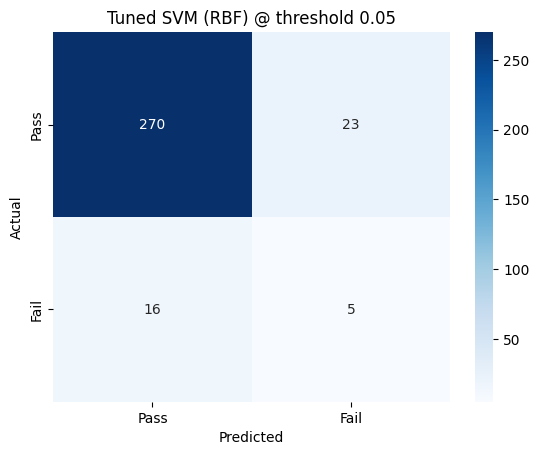

              Model  ROC-AUC  PR-AUC
Baseline (majority)    0.500   0.067
Logistic Regression    0.654   0.116
          SVM (RBF)    0.682   0.227
      Random Forest    0.801   0.244
    Tuned SVM (RBF)    0.693   0.155


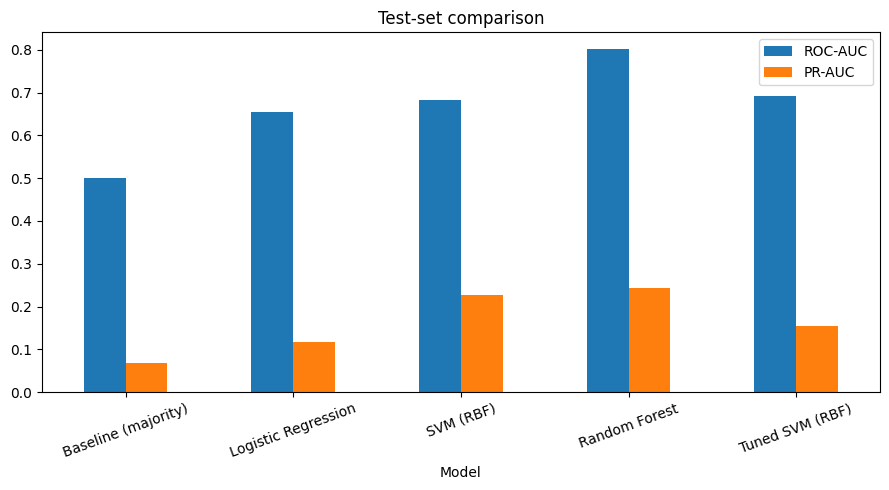

In [59]:
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score,
                             average_precision_score)

test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

print("ROC-AUC: %.3f | PR-AUC: %.3f (random-guess PR-AUC = %.3f)" %
      (roc_auc_score(y_test, test_prob), average_precision_score(y_test, test_prob), y_test.mean()))
print(classification_report(y_test, test_pred, target_names=["Pass", "Fail"], zero_division=0))

cm = confusion_matrix(y_test, test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pass", "Fail"], yticklabels=["Pass", "Fail"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Tuned %s @ threshold %.2f" % (TUNE_MODEL, best_threshold))
plt.show()

# Comparison table is computed
final_rows = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pr = pipe.predict_proba(X_test)[:, 1]
    final_rows.append({"Model": name, "ROC-AUC": roc_auc_score(y_test, pr),
                       "PR-AUC": average_precision_score(y_test, pr)})
final_rows.append({"Model": "Tuned " + TUNE_MODEL, "ROC-AUC": roc_auc_score(y_test, test_prob),
                   "PR-AUC": average_precision_score(y_test, test_prob)})
final_df = pd.DataFrame(final_rows).round(3)
print(final_df.to_string(index=False))

final_df.set_index("Model").plot(kind="bar", figsize=(9, 5))
plt.title("Test-set comparison"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## 10. Error analysis

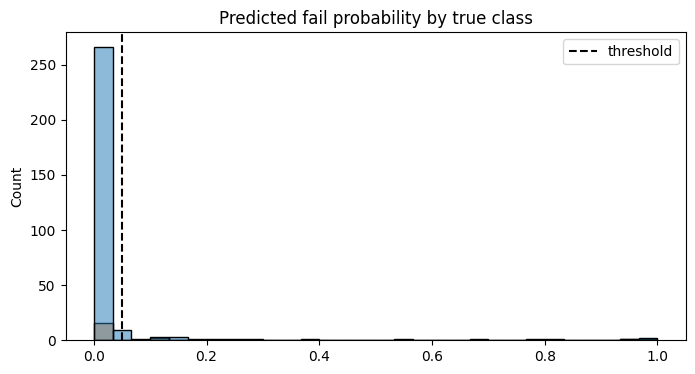

Missed fails: 16 | Caught fails: 5
        n_missing   hour
y pred                  
0 0         25.94  11.18
  1         21.91  12.57
1 0         25.75  15.62
  1         33.60  13.60


In [60]:
# 1. How well are the two classes separated?
plt.figure(figsize=(8, 4))
sns.histplot(x=test_prob, hue=y_test.map({0: "Pass", 1: "Fail"}).values, bins=30, common_norm=False)
plt.axvline(best_threshold, color="k", ls="--", label="threshold")
plt.legend(); plt.title("Predicted fail probability by true class"); plt.show()

# 2. Missed defects (false negatives) vs caught defects
err = X_test.copy()
err["y"], err["prob"], err["pred"] = y_test, test_prob, test_pred
fn = err[(err.y == 1) & (err.pred == 0)]
tp = err[(err.y == 1) & (err.pred == 1)]
print("Missed fails: %d | Caught fails: %d" % (len(fn), len(tp)))
print(err.groupby(["y", "pred"])[["n_missing", "hour"]].mean().round(2))
